In [4]:
import pandas as pd 
import numpy as np

cta_delays = pd.read_csv("./../data/bus_delay_notices.csv")

In [3]:
cta_delays.head()

,Bus Route,Delay Notice Time,Delay End Notice Time,Time Delayed,Notes
0,55,"October 13, 2025 at 8:07 PM","October 13, 2025 at 9:13 PM",1:06,Reroute due to fire department activity; south...
1,79,"October 14, 2025 at 4:33 AM","October 14, 2025 at 5:40 AM",1:07,Reroute due to blockage
2,71,"October 14, 2025 at 7:44 AM","October 14, 2025 at 8:53 AM",1:09,Reroute due to blockage; southbound buses not ...
3,86,"October 14, 2025 at 10:05 AM","October 14, 2025 at 1:47 PM",3:42,Reroute due to blockage; southbound buses not ...
4,34,"October 14, 2025 at 4:35 PM","October 14, 2025 at 5:50 PM",1:15,Reroute due to blockage


In [8]:
cta_delays = cta_delays.assign(
    time_minutes=lambda x: pd.to_timedelta(x['Time Delayed'] + ":00").dt.total_seconds() / 60
)
cta_delays.head()

,Bus Route,Delay Notice Time,Delay End Notice Time,Time Delayed,Notes,time_minutes
0,55,"October 13, 2025 at 8:07 PM","October 13, 2025 at 9:13 PM",1:06,Reroute due to fire department activity; south...,66.0
1,79,"October 14, 2025 at 4:33 AM","October 14, 2025 at 5:40 AM",1:07,Reroute due to blockage,67.0
2,71,"October 14, 2025 at 7:44 AM","October 14, 2025 at 8:53 AM",1:09,Reroute due to blockage; southbound buses not ...,69.0
3,86,"October 14, 2025 at 10:05 AM","October 14, 2025 at 1:47 PM",3:42,Reroute due to blockage; southbound buses not ...,222.0
4,34,"October 14, 2025 at 4:35 PM","October 14, 2025 at 5:50 PM",1:15,Reroute due to blockage,75.0


In [28]:
#cta_delays['time_minutes'].mean()
cta_delays['time_minutes'].median()
cta_delays['time_minutes'].min()
cta_delays['time_minutes'].max()


np.float64(10616.0)

Matplotlib is building the font cache; this may take a moment.


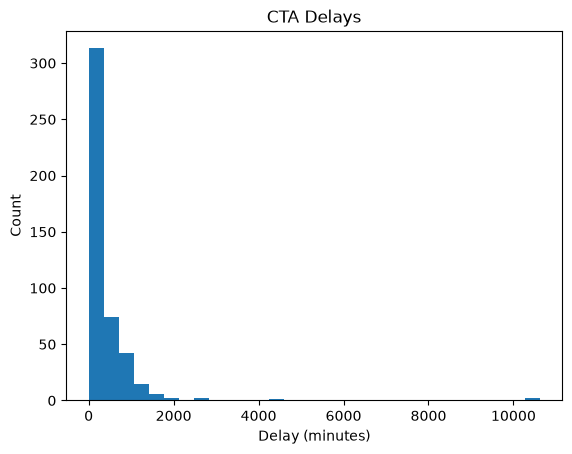

In [19]:
import matplotlib.pyplot as plt

plt.hist(cta_delays['time_minutes'], bins=30)
plt.xlabel('Delay (minutes)')
plt.ylabel('Count')
plt.title('CTA Delays')
plt.show()

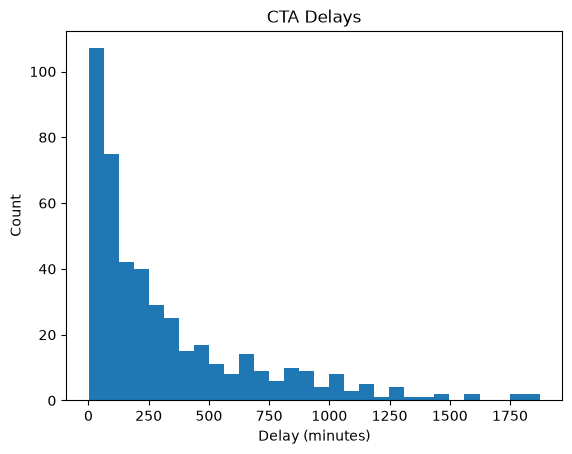

In [23]:
#clean data to remove outliers 

below_2000 = cta_delays[cta_delays['time_minutes'] <= 2000]

import matplotlib.pyplot as plt

plt.hist(below_2000['time_minutes'], bins=30)
plt.xlabel('Delay (minutes)')
plt.ylabel('Count')
plt.title('CTA Delays')
plt.show()